# OOD Evaluation: CLIP ViT-L/14 + LoRA & Zero-Shot NN Baseline

This notebook evaluates two detectors on the OOD test set:

1. **CLIP + LoRA (fine-tuned)** — the trained model from `deepfake_clip_lora.ipynb`
2. **Zero-Shot CLIP NN** — frozen CLIP nearest-neighbor baseline (Ojha et al.)

The OOD set contains generators the model **never saw during training**
(no Stable Diffusion, no Midjourney), plus real images from a held-out pool.

Metrics and plots follow the same format as the training notebook for
direct comparison in the paper.

## 1. Setup & Installation

In [1]:
%%capture
!pip install -q --upgrade torchao
!pip install -q transformers peft accelerate datasets pillow scikit-learn matplotlib seaborn tqdm

## 2. Configuration

In [2]:
from pathlib import Path

# ── Paths on Google Drive ──
PROJECT_DIR    = Path("/content/drive/MyDrive/Image Processing Project")
CLIP_DIR       = PROJECT_DIR / "CLIP Based"
BEST_MODEL_PT  = CLIP_DIR / "outputs" / "best_model.pt"
TRAIN_META_CSV = CLIP_DIR / "metadata.csv"
TRAIN_ZIP      = CLIP_DIR / "preprocessed_256_outputs" / "archives" / "openfake_split_256.zip"

OOD_DIR        = PROJECT_DIR / "OOD Dataset" / "openfake_ood_test_256"
OOD_IMAGE_ROOT = OOD_DIR
OOD_META_CSV   = OOD_DIR / "metadata" / "ood_test_metadata.csv"
OOD_OUTPUT_DIR = PROJECT_DIR / "OOD Dataset" / "evaluation_results"

# ── Model config (must match training exactly) ──
CONFIG = {
    "model_name": "openai/clip-vit-large-patch14",
    "image_size": 224,
    "lora_r": 16,
    "lora_alpha": 32,
    "lora_dropout": 0.1,
    "head_hidden_dim": 256,
    "head_dropout": 0.1,
    "batch_size": 32,
    "seed": 42,
}

print(f"Model checkpoint: {BEST_MODEL_PT}")
print(f"OOD image root:   {OOD_IMAGE_ROOT}")
print(f"OOD metadata:     {OOD_META_CSV}")
print(f"Output dir:       {OOD_OUTPUT_DIR}")

Model checkpoint: /content/drive/MyDrive/Image Processing Project/CLIP Based/outputs/best_model.pt
OOD image root:   /content/drive/MyDrive/Image Processing Project/OOD Dataset/openfake_ood_test_256
OOD metadata:     /content/drive/MyDrive/Image Processing Project/OOD Dataset/openfake_ood_test_256/metadata/ood_test_metadata.csv
Output dir:       /content/drive/MyDrive/Image Processing Project/OOD Dataset/evaluation_results


## 3. Mount Drive & Verify Files

In [3]:
from google.colab import drive
drive.mount("/content/drive")

assert BEST_MODEL_PT.exists(), f"Checkpoint not found: {BEST_MODEL_PT}"
assert OOD_META_CSV.exists(),  f"OOD metadata not found: {OOD_META_CSV}"
assert (OOD_IMAGE_ROOT / "ood_test" / "real").exists(), "OOD real/ folder missing"
assert (OOD_IMAGE_ROOT / "ood_test" / "fake").exists(), "OOD fake/ folder missing"

OOD_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

n_real = len(list((OOD_IMAGE_ROOT / "ood_test" / "real").glob("*.jpg")))
n_fake = len(list((OOD_IMAGE_ROOT / "ood_test" / "fake").glob("*.jpg")))
print(f"OOD test set: {n_real} real + {n_fake} fake = {n_real + n_fake} total")
print("All files verified.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
OOD test set: 0 real + 0 fake = 0 total
All files verified.


## 4. Imports & Reproducibility

In [4]:
import json
import random
import zipfile
import warnings
from datetime import datetime

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.nn.functional import normalize as F_normalize
from torch.utils.data import Dataset, DataLoader
from PIL import Image

from transformers import CLIPModel, CLIPProcessor
from peft import LoraConfig, get_peft_model

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
)
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")

class Log:
    def info(self, msg): print(f"[INFO] {msg}")
    def warning(self, msg): print(f"[WARN] {msg}")
log = Log()

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True

seed_everything(CONFIG["seed"])
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
log.info(f"Device: {DEVICE}")
if torch.cuda.is_available():
    log.info(f"GPU: {torch.cuda.get_device_name(0)}")

[INFO] Device: cuda
[INFO] GPU: Tesla T4


## 5. Dataset

In [5]:
class DeepfakeDataset(Dataset):
    def __init__(self, image_root, split, processor, metadata_df, max_samples=None):
        self.processor = processor
        self.samples = []
        split_dir = Path(image_root) / split
        label_map = {"real": 0, "fake": 1}
        fname_to_model = {}
        if metadata_df is not None:
            for _, row in metadata_df.iterrows():
                fname = Path(str(row["image_path"])).name
                fname_to_model[fname] = row["model"]
        for cls_name, label in label_map.items():
            cls_dir = split_dir / cls_name
            if not cls_dir.exists():
                log.warning(f"Directory missing: {cls_dir}")
                continue
            for fp in sorted(cls_dir.glob("*")):
                if fp.suffix.lower() in (".jpg", ".jpeg", ".png", ".webp", ".bmp"):
                    model_name = fname_to_model.get(fp.name, cls_name)
                    self.samples.append((str(fp), label, model_name))
        if max_samples and len(self.samples) > max_samples:
            random.shuffle(self.samples)
            self.samples = self.samples[:max_samples]
        n_real = sum(1 for _, l, _ in self.samples if l == 0)
        n_fake = sum(1 for _, l, _ in self.samples if l == 1)
        log.info(f"  [{split:>10}] {len(self.samples):>6} images  (real={n_real}, fake={n_fake})")

    def __len__(self): return len(self.samples)

    def __getitem__(self, idx):
        path, label, model_name = self.samples[idx]
        try:
            image = Image.open(path).convert("RGB")
        except Exception:
            image = Image.new("RGB", (CONFIG["image_size"], CONFIG["image_size"]))
        inputs = self.processor(images=image, return_tensors="pt")
        pixel_values = inputs["pixel_values"].squeeze(0)
        return {"pixel_values": pixel_values, "label": torch.tensor(label, dtype=torch.long), "model_name": model_name}

In [6]:
ood_meta = pd.read_csv(OOD_META_CSV)
log.info(f"OOD metadata: {len(ood_meta)} rows, {ood_meta['model'].nunique()} unique models")
print(ood_meta.groupby(['label','model']).size().reset_index(name='count').to_string(index=False))

processor = CLIPProcessor.from_pretrained(CONFIG["model_name"])

log.info("Building OOD dataset...")
ood_ds = DeepfakeDataset(OOD_IMAGE_ROOT, "ood_test", processor, ood_meta)
ood_loader = DataLoader(ood_ds, batch_size=CONFIG["batch_size"], shuffle=False, num_workers=0, pin_memory=True)

[INFO] OOD metadata: 2077 rows, 19 unique models
label             model  count
 fake    aurora-20-1-25     50
 fake       ernie-image     50
 fake ernie-image-turbo     50
 fake   flux.2-klein-9b     50
 fake    frames-23-1-25     50
 fake     gpt-image-1.5     50
 fake       gpt-image-2     50
 fake      ideogram-2.0     50
 fake       illustrious     50
 fake    lumina-17-2-25     50
 fake   nano-banana-pro     50
 fake        recraft-v2     50
 fake        recraft-v3     50
 fake     seedream-v5.0     50
 fake            sora-2     50
 fake             veo-3     50
 fake     wan-video-2.5     50
 fake     z-image-turbo     50
 real              real   1177


preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

The image processor of type `CLIPImageProcessor` is now loaded as a fast processor by default, even if the model checkpoint was saved with a slow processor. This is a breaking change and may produce slightly different outputs. To continue using the slow processor, instantiate this class with `use_fast=False`. 


config.json: 0.00B [00:00, ?B/s]

tokenizer_config.json:   0%|          | 0.00/905 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

[INFO] Building OOD dataset...
[INFO]   [  ood_test]   2077 images  (real=1177, fake=900)


## 6. Model Architecture & Checkpoint Load

In [7]:
class CLIPDeepfakeDetector(nn.Module):
    def __init__(self, config, lora_config):
        super().__init__()
        clip = CLIPModel.from_pretrained(config["model_name"])
        self.vision_model = clip.vision_model
        self.visual_projection = clip.visual_projection
        for p in self.vision_model.parameters(): p.requires_grad = False
        for p in self.visual_projection.parameters(): p.requires_grad = False
        self.vision_model = get_peft_model(self.vision_model, lora_config)
        embed_dim = clip.config.projection_dim
        hidden_dim = config["head_hidden_dim"]
        dropout = config["head_dropout"]
        self.classifier = nn.Sequential(
            nn.LayerNorm(embed_dim), nn.Dropout(dropout),
            nn.Linear(embed_dim, hidden_dim), nn.GELU(),
            nn.Dropout(dropout), nn.Linear(hidden_dim, 2),
        )
    def forward(self, pixel_values):
        vision_out = self.vision_model(pixel_values=pixel_values)
        projected = self.visual_projection(vision_out.pooler_output)
        return self.classifier(projected)

lora_config = LoraConfig(
    r=CONFIG["lora_r"], lora_alpha=CONFIG["lora_alpha"],
    lora_dropout=CONFIG["lora_dropout"],
    target_modules=["q_proj", "v_proj"], bias="none",
)
model = CLIPDeepfakeDetector(CONFIG, lora_config).to(DEVICE)
model.load_state_dict(torch.load(BEST_MODEL_PT, map_location=DEVICE))
model.eval()
log.info(f"LoRA model loaded from {BEST_MODEL_PT}")

model.safetensors:   0%|          | 0.00/1.71G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/590 [00:00<?, ?it/s]

CLIPModel LOAD REPORT from: openai/clip-vit-large-patch14
Key                                  | Status     |  | 
-------------------------------------+------------+--+-
vision_model.embeddings.position_ids | UNEXPECTED |  | 
text_model.embeddings.position_ids   | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[INFO] LoRA model loaded from /content/drive/MyDrive/Image Processing Project/CLIP Based/outputs/best_model.pt


## 7. Shared Evaluation & Metrics Functions

In [8]:
def full_evaluate(model, loader, device, desc="Evaluating"):
    model.eval()
    all_preds, all_labels, all_probs, all_models = [], [], [], []
    with torch.no_grad():
        for batch in tqdm(loader, desc=desc, leave=False):
            pv = batch["pixel_values"].to(device)
            logits = model(pv)
            probs = torch.softmax(logits, dim=1)[:, 1]
            preds = logits.argmax(dim=1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(batch["label"].numpy())
            all_probs.extend(probs.cpu().numpy())
            all_models.extend(batch["model_name"])
    return np.array(all_labels), np.array(all_preds), np.array(all_probs), np.array(all_models)

def compute_metrics_table(y_true, y_pred, y_prob, label_names=("Real", "Fake")):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average=None, zero_division=0)
    rec  = recall_score(y_true, y_pred, average=None, zero_division=0)
    f1   = f1_score(y_true, y_pred, average=None, zero_division=0)
    prec_m = precision_score(y_true, y_pred, average="macro", zero_division=0)
    rec_m  = recall_score(y_true, y_pred, average="macro", zero_division=0)
    f1_m   = f1_score(y_true, y_pred, average="macro", zero_division=0)
    try: auc = roc_auc_score(y_true, y_prob)
    except ValueError: auc = float("nan")
    cm = confusion_matrix(y_true, y_pred)
    rows = []
    for i, name in enumerate(label_names):
        if i < len(prec):
            rows.append({"Class": name, "Precision": round(float(prec[i]),4), "Recall": round(float(rec[i]),4), "F1": round(float(f1[i]),4), "Support": int((y_true==i).sum())})
    rows.append({"Class": "Macro Avg", "Precision": round(prec_m,4), "Recall": round(rec_m,4), "F1": round(f1_m,4), "Support": len(y_true)})
    return {"table": pd.DataFrame(rows).set_index("Class"), "accuracy": round(acc,4), "roc_auc": round(auc,4) if not np.isnan(auc) else "N/A", "confusion_matrix": cm}

def print_metrics(result, title):
    print(f"\n{'='*60}")
    print(f"  {title}")
    print(f"{'='*60}")
    print(f"  Accuracy: {result['accuracy']}")
    print(f"  ROC AUC:  {result['roc_auc']}")
    print()
    print(result["table"].to_string())
    print(f"{'='*60}")

## 8. LoRA Model — Inference

In [9]:
ood_labels, ood_preds, ood_probs, ood_models = full_evaluate(model, ood_loader, DEVICE, "LoRA OOD Eval")
log.info(f"LoRA inference complete: {len(ood_labels)} samples")

LoRA OOD Eval:   0%|          | 0/65 [00:00<?, ?it/s]

[INFO] LoRA inference complete: 2077 samples


## 9. LoRA — Overall Results

In [10]:
overall_lora = compute_metrics_table(ood_labels, ood_preds, ood_probs)
print_metrics(overall_lora, "LORA FINE-TUNED — OOD OVERALL")


  LORA FINE-TUNED — OOD OVERALL
  Accuracy: 0.5908
  ROC AUC:  0.8345

           Precision  Recall      F1  Support
Class                                        
Real          0.9529  0.2923  0.4473     1177
Fake          0.5146  0.9811  0.6751      900
Macro Avg     0.7337  0.6367  0.5612     2077


## 10. LoRA — Per-Generator Breakdown

In [11]:
unique_generators = sorted(set(ood_models))
lora_gen_results = {}

for gen in unique_generators:
    mask = ood_models == gen
    if mask.sum() == 0: continue
    result = compute_metrics_table(ood_labels[mask], ood_preds[mask], ood_probs[mask])
    lora_gen_results[gen] = result
    print_metrics(result, f"LORA — GENERATOR: {gen}  (n={mask.sum()})")


  LORA — GENERATOR: fake  (n=900)
  Accuracy: 0.9811
  ROC AUC:  N/A

           Precision  Recall      F1  Support
Class                                        
Real             0.0  0.0000  0.0000        0
Fake             1.0  0.9811  0.9905      900
Macro Avg        0.5  0.4906  0.4952      900

  LORA — GENERATOR: real  (n=1177)
  Accuracy: 0.2923
  ROC AUC:  N/A

           Precision  Recall      F1  Support
Class                                        
Real             1.0  0.2923  0.4523     1177
Fake             0.0  0.0000  0.0000        0
Macro Avg        0.5  0.1461  0.2262     1177


## 11. LoRA — Confusion Matrices

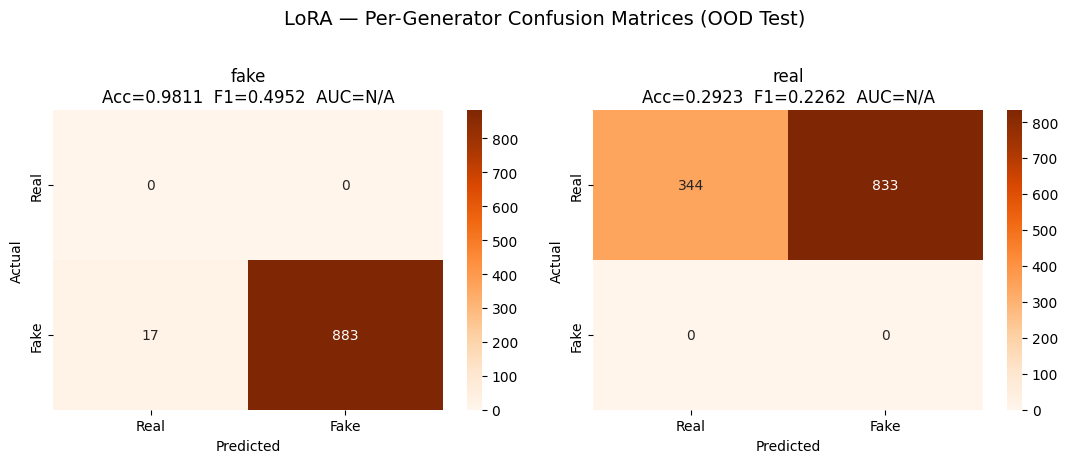

In [12]:
n_gen = len(lora_gen_results)
fig, axes = plt.subplots(1, n_gen, figsize=(5.5 * n_gen, 4.5))
if n_gen == 1: axes = [axes]

for ax, (gen, res) in zip(axes, sorted(lora_gen_results.items())):
    cm = res["confusion_matrix"]
    sns.heatmap(cm, annot=True, fmt="d", cmap="Oranges",
                xticklabels=["Real", "Fake"], yticklabels=["Real", "Fake"], ax=ax)
    macro_f1 = res["table"].loc["Macro Avg", "F1"]
    ax.set_title(f"{gen}\nAcc={res['accuracy']}  F1={macro_f1}  AUC={res['roc_auc']}")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.suptitle("LoRA — Per-Generator Confusion Matrices (OOD Test)", fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig(OOD_OUTPUT_DIR / "lora_confusion_matrices_per_generator.png", dpi=150, bbox_inches="tight")
plt.show()

## 12. LoRA — F1 Bar Chart

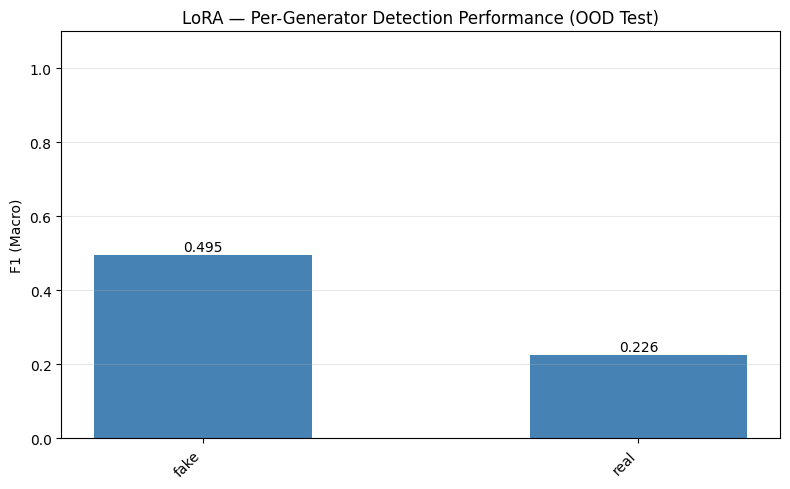

In [13]:
gen_names = sorted(lora_gen_results.keys())
gen_f1s = [lora_gen_results[g]["table"].loc["Macro Avg", "F1"] for g in gen_names]

x = np.arange(len(gen_names))
fig, ax = plt.subplots(figsize=(max(8, len(gen_names) * 1.2), 5))
bars = ax.bar(x, gen_f1s, color="steelblue", width=0.5)

for bar in bars:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
            f"{bar.get_height():.3f}", ha="center", fontsize=10)

ax.set_xticks(x)
ax.set_xticklabels(gen_names, rotation=45, ha="right")
ax.set_ylim(0, 1.1)
ax.set_ylabel("F1 (Macro)")
ax.set_title("LoRA — Per-Generator Detection Performance (OOD Test)")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(OOD_OUTPUT_DIR / "lora_per_generator_bar_chart.png", dpi=150, bbox_inches="tight")
plt.show()

---
## 13. Zero-Shot CLIP NN Baseline

From Ojha et al. — embed a bank of known real/fake images using frozen CLIP,
then classify each test image by whether its nearest neighbor is real or fake.

We use the **training set** as the reference bank.

In [17]:
# ============================================================
# ZERO-SHOT BASELINE: CLIP text-image similarity
# ============================================================
# From deepfake_clip_lora.ipynb Section 17.
# Compare each image's CLIP embedding against two text prompts:
#   - "a real photograph"      → class 0 (real)
#   - "an AI generated image"  → class 1 (fake)
# The class with higher cosine similarity wins.
# ============================================================

def zero_shot_evaluate(model_name, loader, device, desc="Zero-shot"):
    """
    Zero-shot deepfake detection using CLIP's text-image similarity.
    """
    from transformers import CLIPModel, CLIPProcessor

    clip = CLIPModel.from_pretrained(model_name).to(device)
    proc = CLIPProcessor.from_pretrained(model_name)
    clip.eval()

    # Encode the two class prompts once
    text_inputs = proc(
        text=["a real photograph", "an AI generated image"],
        return_tensors="pt", padding=True,
    ).to(device)

    with torch.no_grad():
        text_features = clip.get_text_features(**text_inputs)
        if not isinstance(text_features, torch.Tensor):
            text_features = text_features.pooler_output
        text_features = text_features / text_features.norm(dim=-1, keepdim=True)

    all_preds, all_labels, all_probs, all_models = [], [], [], []

    with torch.no_grad():
        for batch in tqdm(loader, desc=desc, leave=False):
            pixel_values = batch["pixel_values"].to(device)
            labels = batch["label"]

            # Get image features
            image_features = clip.get_image_features(pixel_values=pixel_values)
            if not isinstance(image_features, torch.Tensor):
                image_features = image_features.pooler_output
            image_features = image_features / image_features.norm(dim=-1, keepdim=True)

            # Cosine similarity with each text prompt → [batch, 2]
            similarity = image_features @ text_features.T

            # Higher similarity to "AI generated image" → class 1 (fake)
            preds = similarity.argmax(dim=1)
            probs = torch.softmax(similarity * 100, dim=1)[:, 1]  # scale for softmax

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.numpy())
            all_probs.extend(probs.cpu().numpy())
            all_models.extend(batch["model_name"])

    del clip
    torch.cuda.empty_cache()

    return np.array(all_labels), np.array(all_preds), np.array(all_probs), np.array(all_models)

## 14. Zero-Shot NN — Overall Results

In [18]:
log.info("Running zero-shot CLIP evaluation...")
ood_zs_labels, zs_preds, zs_probs, ood_zs_models = zero_shot_evaluate(
    CONFIG["model_name"], ood_loader, DEVICE, "Zero-Shot OOD"
)
log.info(f"Zero-shot inference complete: {len(ood_zs_labels)} samples")

[INFO] Running zero-shot CLIP evaluation...


Loading weights:   0%|          | 0/590 [00:00<?, ?it/s]

CLIPModel LOAD REPORT from: openai/clip-vit-large-patch14
Key                                  | Status     |  | 
-------------------------------------+------------+--+-
vision_model.embeddings.position_ids | UNEXPECTED |  | 
text_model.embeddings.position_ids   | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Zero-Shot OOD:   0%|          | 0/65 [00:00<?, ?it/s]

[INFO] Zero-shot inference complete: 2077 samples


In [24]:
overall_zs = compute_metrics_table(ood_zs_labels, zs_preds, zs_probs)
print_metrics(overall_zs, "ZERO-SHOT CLIP — OOD OVERALL")


  ZERO-SHOT CLIP — OOD OVERALL
  Accuracy: 0.4338
  ROC AUC:  0.5208

           Precision  Recall      F1  Support
Class                                        
Real          0.5023  0.0909  0.1540     1177
Fake          0.4260  0.8822  0.5745      900
Macro Avg     0.4642  0.4866  0.3642     2077


## 15. Zero-Shot NN — Per-Generator Breakdown

In [19]:
zs_gen_results = {}
for gen in unique_generators:
    mask = ood_zs_models == gen
    if mask.sum() == 0: continue
    result = compute_metrics_table(ood_zs_labels[mask], zs_preds[mask], zs_probs[mask])
    zs_gen_results[gen] = result
    print_metrics(result, f"ZERO-SHOT NN — GENERATOR: {gen}  (n={mask.sum()})")


  ZERO-SHOT NN — GENERATOR: fake  (n=900)
  Accuracy: 0.8822
  ROC AUC:  N/A

           Precision  Recall      F1  Support
Class                                        
Real             0.0  0.0000  0.0000        0
Fake             1.0  0.8822  0.9374      900
Macro Avg        0.5  0.4411  0.4687      900

  ZERO-SHOT NN — GENERATOR: real  (n=1177)
  Accuracy: 0.0909
  ROC AUC:  N/A

           Precision  Recall      F1  Support
Class                                        
Real             1.0  0.0909  0.1667     1177
Fake             0.0  0.0000  0.0000        0
Macro Avg        0.5  0.0455  0.0833     1177


## 16. Zero-Shot NN — Confusion Matrices

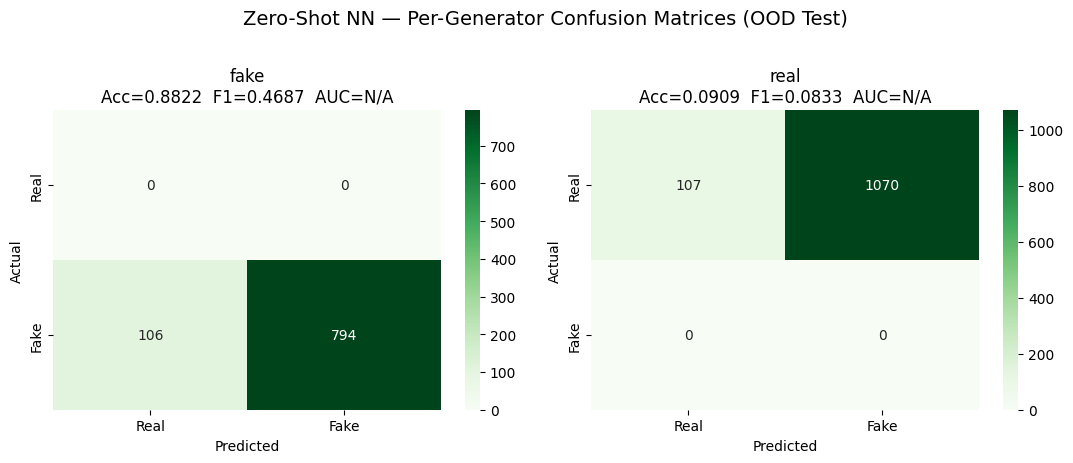

In [20]:
n_gen = len(zs_gen_results)
fig, axes = plt.subplots(1, n_gen, figsize=(5.5 * n_gen, 4.5))
if n_gen == 1: axes = [axes]

for ax, (gen, res) in zip(axes, sorted(zs_gen_results.items())):
    cm = res["confusion_matrix"]
    sns.heatmap(cm, annot=True, fmt="d", cmap="Greens",
                xticklabels=["Real", "Fake"], yticklabels=["Real", "Fake"], ax=ax)
    macro_f1 = res["table"].loc["Macro Avg", "F1"]
    ax.set_title(f"{gen}\nAcc={res['accuracy']}  F1={macro_f1}  AUC={res['roc_auc']}")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.suptitle("Zero-Shot NN — Per-Generator Confusion Matrices (OOD Test)", fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig(OOD_OUTPUT_DIR / "zs_confusion_matrices_per_generator.png", dpi=150, bbox_inches="tight")
plt.show()

## 17. Comparison: LoRA vs Zero-Shot NN

In [21]:
comparison_rows = []
for gen in unique_generators:
    mask = ood_models == gen
    n = int(mask.sum())
    lr = lora_gen_results.get(gen)
    zr = zs_gen_results.get(gen)
    comparison_rows.append({
        "Generator": gen, "N": n,
        "LoRA Acc": lr["accuracy"] if lr else "N/A",
        "LoRA F1":  lr["table"].loc["Macro Avg", "F1"] if lr else "N/A",
        "LoRA AUC": lr["roc_auc"] if lr else "N/A",
        "ZS-NN Acc": zr["accuracy"] if zr else "N/A",
        "ZS-NN F1":  zr["table"].loc["Macro Avg", "F1"] if zr else "N/A",
        "ZS-NN AUC": zr["roc_auc"] if zr else "N/A",
    })

comparison_df = pd.DataFrame(comparison_rows)
print("\n" + "=" * 100)
print("  COMPARISON: LoRA Fine-Tuned vs Zero-Shot NN (OOD Test)")
print("=" * 100)
print(comparison_df.to_string(index=False))
print("=" * 100)


  COMPARISON: LoRA Fine-Tuned vs Zero-Shot NN (OOD Test)
Generator    N  LoRA Acc  LoRA F1 LoRA AUC  ZS-NN Acc  ZS-NN F1 ZS-NN AUC
     fake  900    0.9811   0.4952      N/A     0.8822    0.4687       N/A
     real 1177    0.2923   0.2262      N/A     0.0909    0.0833       N/A


## 18. Side-by-Side F1 Bar Chart

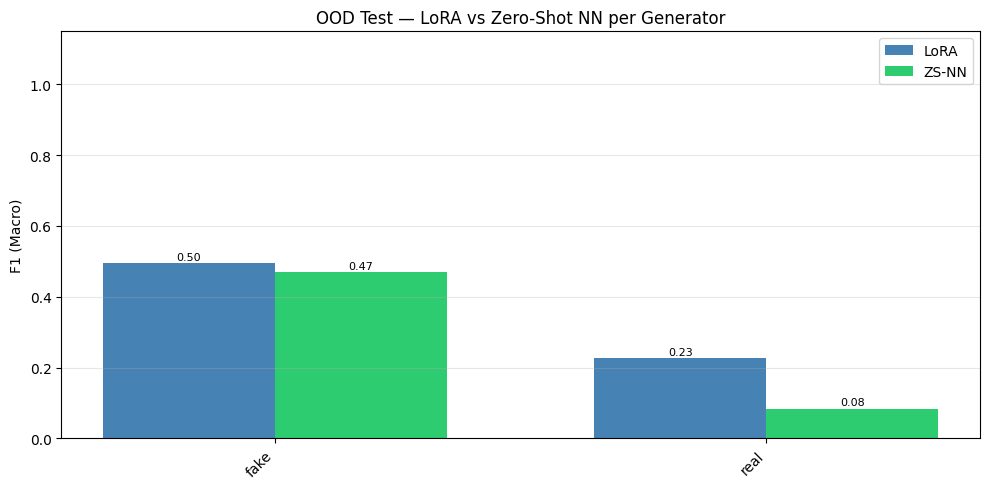

In [22]:
gen_names = sorted(lora_gen_results.keys())
lora_f1s = [lora_gen_results[g]["table"].loc["Macro Avg", "F1"] for g in gen_names]
zs_f1s   = [zs_gen_results[g]["table"].loc["Macro Avg", "F1"] if g in zs_gen_results else 0 for g in gen_names]

x = np.arange(len(gen_names))
width = 0.35
fig, ax = plt.subplots(figsize=(max(10, len(gen_names) * 1.5), 5))
bars1 = ax.bar(x - width/2, lora_f1s, width, label="LoRA", color="steelblue")
bars2 = ax.bar(x + width/2, zs_f1s,   width, label="ZS-NN", color="#2ecc71")

for bar in bars1:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
            f"{bar.get_height():.2f}", ha="center", fontsize=8)
for bar in bars2:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
            f"{bar.get_height():.2f}", ha="center", fontsize=8)

ax.set_xticks(x)
ax.set_xticklabels(gen_names, rotation=45, ha="right")
ax.set_ylim(0, 1.15)
ax.set_ylabel("F1 (Macro)")
ax.set_title("OOD Test — LoRA vs Zero-Shot NN per Generator")
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(OOD_OUTPUT_DIR / "comparison_bar_chart.png", dpi=150, bbox_inches="tight")
plt.show()

## 19. Save All Results

In [25]:
def table_to_dict(df):
    return df.reset_index().to_dict(orient="records")

results_to_save = {
    "evaluation_type": "OOD (unseen generators)",
    "checkpoint": str(BEST_MODEL_PT),
    "ood_dataset": str(OOD_DIR),
    "lora_overall": {
        "metrics": table_to_dict(overall_lora["table"]),
        "accuracy": overall_lora["accuracy"],
        "roc_auc": overall_lora["roc_auc"],
        "confusion_matrix": overall_lora["confusion_matrix"].tolist(),
    },
    "lora_per_generator": {
        n: {"metrics": table_to_dict(r["table"]), "accuracy": r["accuracy"], "roc_auc": r["roc_auc"], "confusion_matrix": r["confusion_matrix"].tolist()}
        for n, r in lora_gen_results.items()
    },
    "zeroshot_nn_overall": {
        "metrics": table_to_dict(overall_zs["table"]),
        "accuracy": overall_zs["accuracy"],
        "roc_auc": overall_zs["roc_auc"],
        "confusion_matrix": overall_zs["confusion_matrix"].tolist(),
    },
    "zeroshot_nn_per_generator": {
        n: {"metrics": table_to_dict(r["table"]), "accuracy": r["accuracy"], "roc_auc": r["roc_auc"], "confusion_matrix": r["confusion_matrix"].tolist()}
        for n, r in zs_gen_results.items()
    },
    "comparison_table": comparison_df.to_dict(orient="records"),
    "timestamp": datetime.now().isoformat(),
}

with open(OOD_OUTPUT_DIR / "ood_results.json", "w") as f:
    json.dump(results_to_save, f, indent=2, default=str)

comparison_df.to_csv(OOD_OUTPUT_DIR / "ood_comparison_table.csv", index=False)

print(f"\nAll results saved to: {OOD_OUTPUT_DIR}")
print(f"  • ood_results.json")
print(f"  • ood_comparison_table.csv")
print(f"  • lora_confusion_matrices_per_generator.png")
print(f"  • lora_per_generator_bar_chart.png")
print(f"  • zs_confusion_matrices_per_generator.png")
print(f"  • comparison_bar_chart.png")


All results saved to: /content/drive/MyDrive/Image Processing Project/OOD Dataset/evaluation_results
  • ood_results.json
  • ood_comparison_table.csv
  • lora_confusion_matrices_per_generator.png
  • lora_per_generator_bar_chart.png
  • zs_confusion_matrices_per_generator.png
  • comparison_bar_chart.png
